In [ ]:
from __future__ import annotations

import gc
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    auc as sklearn_auc,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold, train_test_split, GridSearchCV, ParameterGrid, cross_val_score
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.preprocessing import LabelEncoder, MinMaxScaler, label_binarize

try:
    from imblearn.pipeline import Pipeline as ImbPipeline
    from imblearn.over_sampling import SMOTE
except ImportError:
    pass

## KONFIGURASI EKSPERIMEN


In [ ]:
NUM_CLASSES = 4
USE_SMOTE = False

warnings.filterwarnings('ignore')

## SETUP PATH


In [ ]:
def print_ram_usage(label: str = '') -> None:
    """Tampilkan penggunaan RAM saat ini sebagai progress bar di terminal."""
    try:
        import psutil
        mem = psutil.virtual_memory()
        used_gb  = (mem.total - mem.available) / 1024**3
        total_gb = mem.total / 1024**3
        pct      = mem.percent
        bar_len  = 30
        filled   = int(bar_len * pct / 100)
        bar      = '█' * filled + '░' * (bar_len - filled)
        status   = '[KRITIS]' if pct > 85 else ('[TINGGI]' if pct > 70 else '[AMAN]')
        tag      = f' [{label}]' if label else ''
        print(f'  RAM{tag}: [{bar}] {used_gb:.1f}/{total_gb:.1f} GB ({pct:.1f}%) {status}')
    except ImportError:
        pass

try:
    from google.colab import drive
    try:
        drive.mount('/content/drive')
        IN_COLAB = True
        BASE_DIR = Path('/content/drive/MyDrive/skripsi/data')
        print('[INFO] Google Drive berhasil di-mount.')
    except ValueError as mount_err:
        IN_COLAB = True
        BASE_DIR = Path('/content/skripsi_data')
        BASE_DIR.mkdir(parents=True, exist_ok=True)
        print(f'[PERINGATAN] Google Drive GAGAL di-mount! Error: {mount_err}')
        print('   Fallback ke /content/skripsi_data/ (HILANG saat sesi berakhir!)')
except ImportError:
    IN_COLAB = False
    BASE_DIR = Path('./data')

Mounted at /content/drive
[INFO] Google Drive berhasil di-mount.


In [ ]:
class_suffix = f'_{NUM_CLASSES}class'
smote_suffix = '_SMOTE' if USE_SMOTE else '_NoSMOTE'
suffix = class_suffix + smote_suffix

MERGED_FILE      = BASE_DIR / 'clinvar_dbnsfp_merged.csv'
MODEL_PATH       = BASE_DIR / f'random_forest_model{suffix}.pkl'
RESULTS_PATH     = BASE_DIR / f'training_results{suffix}.csv'

LAMPIRAN_DIR     = BASE_DIR / 'Lampiran_Skripsi'
LAMPIRAN_DIR.mkdir(parents=True, exist_ok=True)

EVAL_REPORT_PATH = LAMPIRAN_DIR / f'evaluation_report_multiclass{suffix}.csv'
CKPT_FEAT_IMP    = BASE_DIR / f'ckpt_feature_importance{suffix}.joblib'
CKPT_TRIALS      = BASE_DIR / f'ckpt_tuning_trials{suffix}.csv'
CKPT_BEST_MDL    = BASE_DIR / f'ckpt_best_model{suffix}.joblib'
LAMPIRAN_CV_TRIALS_PATH = LAMPIRAN_DIR / f'cv_81_trials{suffix}.csv'

## HELPER: Tabel box dengan garis Unicode (konsisten antar pipeline)


In [ ]:
def print_box_table(df: pd.DataFrame, max_col_width: int = 20) -> None:
    """Cetak DataFrame sebagai tabel box rapi dengan garis Unicode."""
    cols = list(df.columns)
    widths = []
    for col in cols:
        max_data = df[col].astype(str).str.len().max() if len(df) > 0 else 0
        widths.append(min(max_col_width, max(len(str(col)), int(max_data), 3)))

    def fmt_row(cells):
        parts = [f' {str(c)[:widths[i]].ljust(widths[i])} ' for i, c in enumerate(cells)]
        return '│' + '│'.join(parts) + '│'

    def border(left, mid, right):
        return left + mid.join('─' * (w + 2) for w in widths) + right

    print(border('┌', '┬', '┐'))
    print(fmt_row(cols))
    print(border('├', '┼', '┤'))
    for _, row in df.iterrows():
        print(fmt_row(row.tolist()))
    print(border('└', '┴', '┘'))


def print_kv_table(data: dict, key_label: str = 'Item', val_label: str = 'Nilai') -> None:
    """Cetak dictionary sebagai tabel 2-kolom bergaris Unicode."""
    kw = max(len(key_label), max((len(str(k)) for k in data.keys()), default=0))
    vw = max(len(val_label), max((len(str(v)) for v in data.values()), default=0))

    def border(left, mid, right, fill):
        return left + fill * (kw + 2) + mid + fill * (vw + 2) + right

    print(border('┌', '┬', '┐', '─'))
    print(f'│ {key_label.ljust(kw)} │ {val_label.ljust(vw)} │')
    print(border('├', '┼', '┤', '─'))
    for k, v in data.items():
        print(f'│ {str(k).ljust(kw)} │ {str(v).ljust(vw)} │')
    print(border('└', '┴', '┘', '─'))


print('=' * 60)
print('TAHAP 4: FEATURE SELECTION, TRAINING, DAN VALIDASI MODEL')
print('=' * 60)

TAHAP 4: FEATURE SELECTION, TRAINING, DAN VALIDASI MODEL


## 1. MUAT DATA


In [ ]:
# Memastikan file merged sudah ada
if not MERGED_FILE.exists():
    raise FileNotFoundError(f'File tidak ditemukan: {MERGED_FILE}. Pastikan Tahap 3 sudah selesai.')

print('\nMemuat data gabungan ClinVar + dbNSFP...')
df = pd.read_csv(MERGED_FILE)

if 'MetaSVM_score' in df.columns and 'MetaSVM' not in df.columns:
    print("\n[HOTFIX] Memperbaiki kolom 'MetaSVM_score' menjadi 'MetaSVM' on-the-fly...")
    df.rename(columns={'MetaSVM_score': 'MetaSVM'}, inplace=True)

    def _extract_max_score(value: object) -> float:
        if pd.isna(value) or str(value).strip() in {'.', '', 'nan'}:
            return np.nan
        scores = []
        for item in str(value).split(';'):
            item = item.strip()
            if item and item != '.':
                try:
                    scores.append(float(item))
                except ValueError:
                    pass
        return max(scores) if scores else np.nan

    df['MetaSVM'] = df['MetaSVM'].apply(_extract_max_score)
    df['MetaSVM'] = pd.to_numeric(df['MetaSVM'], errors='coerce')

    print("         Menyimpan kembali CSV yang sudah diperbaiki agar permanen...")
    df.to_csv(MERGED_FILE, index=False)

print('\n+-- RINGKASAN DATA YANG DIMUAT --')
print_kv_table({
    'Total Baris'   : f'{len(df):,}',
    'Total Kolom'   : str(df.shape[1]),
    'Ukuran di RAM' : f'{df.memory_usage(deep=True).sum() / 1024**2:.1f} MB',
    'Missing Values': f'{df.isnull().sum().sum():,} sel',
}, key_label='Informasi', val_label='Nilai')

print('\n+-- TIPE DATA PER KOLOM --')
print_kv_table({col: str(dt) for col, dt in df.dtypes.items()}, key_label='Kolom', val_label='Tipe Data')

print('\n10 Data Teratas:')
print_box_table(df.head(10))


Memuat data gabungan ClinVar + dbNSFP...

+-- RINGKASAN DATA YANG DIMUAT --
┌────────────────┬─────────────┐
│ Informasi      │ Nilai       │
├────────────────┼─────────────┤
│ Total Baris    │ 357,191     │
│ Total Kolom    │ 13          │
│ Ukuran di RAM  │ 92.3 MB     │
│ Missing Values │ 866,715 sel │
└────────────────┴─────────────┘

+-- TIPE DATA PER KOLOM --
┌─────────────┬───────────┐
│ Kolom       │ Tipe Data │
├─────────────┼───────────┤
│ VariationID │ int64     │
│ chr         │ object    │
│ pos         │ int64     │
│ ref         │ object    │
│ alt         │ object    │
│ label       │ object    │
│ SIFT        │ float64   │
│ PolyPhen    │ float64   │
│ MetaSVM     │ float64   │
│ REVEL       │ float64   │
│ CADD        │ float64   │
│ PhyloP      │ float64   │
│ MAF         │ float64   │
└─────────────┴───────────┘

10 Data Teratas:
┌─────────────┬─────┬─────────┬─────┬─────┬───────────────────┬───────┬──────────┬─────────┬───────┬──────┬────────┬─────┐
│ VariationID 

## 2. PERSIAPAN FITUR & LABEL


In [ ]:
# Memastikan kolom fitur tersedia dan berupa angka
ESSENTIAL_FEATURES = ['CADD', 'SIFT', 'PolyPhen', 'MAF', 'REVEL', 'MetaSVM', 'PhyloP']

available_features = [f for f in ESSENTIAL_FEATURES if f in df.columns]
missing_feats = [f for f in ESSENTIAL_FEATURES if f not in df.columns]
if missing_feats:
    print(f'\n[PERINGATAN] Fitur berikut tidak ada di CSV (mungkin pipeline 3 lama): {missing_feats}')
    print('  Hanya fitur yang tersedia yang akan digunakan.')

print('\n+-- FITUR YANG DIGUNAKAN --')
print_kv_table(
    {f: ('Ada' if f in available_features else 'Tidak ada') for f in ESSENTIAL_FEATURES},
    key_label='Fitur', val_label='Status'
)

for col in available_features:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Membuang kategori VUS
allowed_labels = ['Benign', 'Likely benign', 'Likely pathogenic', 'Pathogenic']
df = df[df['label'].isin(allowed_labels)].copy()

if NUM_CLASSES == 2:
    print('\n[INFO] Menggabungkan kelas (Likely benign -> Benign, Likely pathogenic -> Pathogenic) untuk mode 2 Kelas...')
    df['label'] = df['label'].replace({
        'Likely benign': 'Benign',
        'Likely pathogenic': 'Pathogenic'
    })

label_encoder = LabelEncoder()
df['target'] = label_encoder.fit_transform(df['label'])

print('\n+-- LABEL ENCODING --')
# Mengubal label menjadi angka
print_kv_table(
    {cls: int(enc) for cls, enc in zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_))},
    key_label='Label', val_label='Kode'
)

print('\n+-- DISTRIBUSI LABEL --')
print_kv_table({lbl: f'{cnt:,}' for lbl, cnt in df['label'].value_counts().items()}, key_label='Label', val_label='Jumlah')

X = df[available_features]
y = df['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Membagi data latih dan data uji
print('\n+-- SPLIT DATA --')
print_kv_table({
    'Data Training': f'{len(X_train):,} baris',
    'Data Testing' : f'{len(X_test):,} baris',
}, key_label='Set', val_label='Jumlah')

for col in X_train.select_dtypes(include=[np.float64]).columns:
    X_train[col] = X_train[col].astype(np.float32)
    X_test[col]  = X_test[col].astype(np.float32)


+-- FITUR YANG DIGUNAKAN --
┌──────────┬────────┐
│ Fitur    │ Status │
├──────────┼────────┤
│ CADD     │ Ada    │
│ SIFT     │ Ada    │
│ PolyPhen │ Ada    │
│ MAF      │ Ada    │
│ REVEL    │ Ada    │
│ MetaSVM  │ Ada    │
│ PhyloP   │ Ada    │
└──────────┴────────┘

+-- LABEL ENCODING --
┌───────────────────┬──────┐
│ Label             │ Kode │
├───────────────────┼──────┤
│ Benign            │ 0    │
│ Likely benign     │ 1    │
│ Likely pathogenic │ 2    │
│ Pathogenic        │ 3    │
└───────────────────┴──────┘

+-- DISTRIBUSI LABEL --
┌───────────────────┬─────────┐
│ Label             │ Jumlah  │
├───────────────────┼─────────┤
│ Likely benign     │ 138,021 │
│ Likely pathogenic │ 102,630 │
│ Pathogenic        │ 83,795  │
│ Benign            │ 32,745  │
└───────────────────┴─────────┘

+-- SPLIT DATA --
┌───────────────┬───────────────┐
│ Set           │ Jumlah        │
├───────────────┼───────────────┤
│ Data Training │ 285,752 baris │
│ Data Testing  │ 71,439 baris  │
└───

## 3. SELEKSI FITUR


In [ ]:
print('\nSeleksi fitur berbasis korelasi Spearman dan mutual information...')
# Mengecek apakah ada hubungan searah antara fitur dan penyakit.
train_frame = X_train.copy()
train_frame['target'] = y_train.values
spearman_corr = (
    train_frame.corr(method='spearman')['target']
    .drop('target')
    .sort_values(key=lambda s: s.abs(), ascending=False)
)

selected_features = available_features.copy()

# Mengukur seberapa banyak informasi yang diberikan oleh suatu fitur untuk menebak status penyakit
mi_scores = mutual_info_classif(
    X_train[selected_features].fillna(-999),
    y_train, random_state=42,
)
mi_series = pd.Series(mi_scores, index=selected_features).sort_values(ascending=False)

print('\n+-- KORELASI SPEARMAN FITUR vs TARGET --')
print_kv_table({f: f'{c:.4f}' for f, c in spearman_corr.items()}, key_label='Fitur', val_label='Korelasi')
print('\n+-- MUTUAL INFORMATION --')
print_kv_table({f: f'{s:.4f}' for f, s in mi_series.items()}, key_label='Fitur', val_label='MI Score')
print(f'\nFitur terpilih: {selected_features}')


Seleksi fitur berbasis korelasi Spearman dan mutual information...

+-- KORELASI SPEARMAN FITUR vs TARGET --
┌──────────┬──────────┐
│ Fitur    │ Korelasi │
├──────────┼──────────┤
│ CADD     │ 0.7498   │
│ REVEL    │ 0.6513   │
│ MAF      │ -0.6221  │
│ MetaSVM  │ 0.6201   │
│ PolyPhen │ 0.5436   │
│ SIFT     │ -0.5347  │
│ PhyloP   │ 0.4925   │
└──────────┴──────────┘

+-- MUTUAL INFORMATION --
┌──────────┬──────────┐
│ Fitur    │ MI Score │
├──────────┼──────────┤
│ CADD     │ 0.4809   │
│ REVEL    │ 0.3933   │
│ MetaSVM  │ 0.3806   │
│ SIFT     │ 0.2899   │
│ PolyPhen │ 0.2738   │
│ MAF      │ 0.2237   │
│ PhyloP   │ 0.2103   │
└──────────┴──────────┘

Fitur terpilih: ['CADD', 'SIFT', 'PolyPhen', 'MAF', 'REVEL', 'MetaSVM', 'PhyloP']


## 4. MODEL AWAL — FEATURE IMPORTANCE


In [ ]:
# Memuat checkpoint
if CKPT_FEAT_IMP.exists():
    print(f'\n[CHECKPOINT] Memuat feature importance dari: {CKPT_FEAT_IMP}')
    ckpt_fi = joblib.load(CKPT_FEAT_IMP)
    feature_importance = pd.Series(ckpt_fi['feature_importance'])
    print('  Feature importance berhasil dimuat, melewati training model awal.')
else:
    print('\n[TAHAP 3/7] Melatih model awal untuk feature importance...')
    print_ram_usage('sebelum model awal')
    # Menginput nilai kosong dengan imputer
    if USE_SMOTE:
        preliminary_pipeline = ImbPipeline(steps=[
            ('imputer', SimpleImputer(strategy='constant', fill_value=-999)),
            ('scaler',  MinMaxScaler()),
            # membuat data sintetis pada kelas minoritas
            ('smote',   SMOTE(random_state=42)),
            ('rf',      RandomForestClassifier(n_estimators=50, max_depth=15, random_state=42, n_jobs=-1)),
        ])
    else:
        preliminary_pipeline = SkPipeline(steps=[
            ('imputer', SimpleImputer(strategy='constant', fill_value=-999)),
            # Mengubah rentang nilai jadi 0-1
            ('scaler',  MinMaxScaler()),
            # memberi bobot yang besar pada data sedikit
            ('rf',      RandomForestClassifier(
                n_estimators=50, max_depth=15,
                random_state=42, n_jobs=-1,
                class_weight='balanced_subsample',
            )),
        ])
    # melatih model dan mengambil skor feature importance
    preliminary_pipeline.fit(X_train[selected_features], y_train)
    feature_importance = pd.Series(
        preliminary_pipeline.named_steps['rf'].feature_importances_,
        index=selected_features,
    ).sort_values(ascending=False)

    joblib.dump({'feature_importance': feature_importance.to_dict()}, CKPT_FEAT_IMP)
    print(f'  [CHECKPOINT DISIMPAN] {CKPT_FEAT_IMP}')
    del preliminary_pipeline
    gc.collect()
    print_ram_usage('setelah model awal + gc')

print('\n+-- FEATURE IMPORTANCE MODEL AWAL --')
print_kv_table({f: f'{v:.4f}' for f, v in feature_importance.items()}, key_label='Fitur', val_label='Importance')


[CHECKPOINT] Memuat feature importance dari: /content/drive/MyDrive/skripsi/data/ckpt_feature_importance_4class_NoSMOTE.joblib
  Feature importance berhasil dimuat, melewati training model awal.

+-- FEATURE IMPORTANCE MODEL AWAL --
┌──────────┬────────────┐
│ Fitur    │ Importance │
├──────────┼────────────┤
│ CADD     │ 0.3075     │
│ MAF      │ 0.2683     │
│ SIFT     │ 0.1173     │
│ REVEL    │ 0.1083     │
│ MetaSVM  │ 0.0890     │
│ PhyloP   │ 0.0722     │
│ PolyPhen │ 0.0373     │
└──────────┴────────────┘


## 5. TUNING HYPERPARAMETER DENGAN GRIDSEARCHCV


In [1]:
# Menyiapkan kerangka model utama
if USE_SMOTE:
    print('\n[INFO] Menggunakan SMOTE untuk oversampling...')
    model_pipeline = ImbPipeline(steps=[
        ('imputer', SimpleImputer(strategy='constant', fill_value=-999)),
        ('scaler',  MinMaxScaler()),
        ('smote',   SMOTE(random_state=42)),
        ('rf',      RandomForestClassifier(random_state=42, n_jobs=-1)),
    ])
else:
    print('\n[INFO] TANPA SMOTE (menggunakan class_weight=balanced_subsample)...')
    model_pipeline = SkPipeline(steps=[
        ('imputer', SimpleImputer(strategy='constant', fill_value=-999)),
        ('scaler',  MinMaxScaler()),
        ('rf',      RandomForestClassifier(
            random_state=42, n_jobs=-1,
            class_weight='balanced_subsample',
        )),
    ])
# Kombinasi yang akan diuji
param_matrix = {
    'rf__n_estimators': [100, 200, 300],
    'rf__max_depth': [10, 20, 30],
    'rf__min_samples_split': [2, 5, 10],
    'rf__min_samples_leaf': [1, 2, 4],
}
# Sistem 3-Fold Cross-Validation
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
classes = np.sort(y.unique())

print('\n[TAHAP 4/7] Manual Grid Search + 3-Fold CV (Dengan Checkpoint)...')
print_ram_usage('sebelum gridsearch')

param_list = list(ParameterGrid(param_matrix))
total_trials = len(param_list)

results = []
start_idx = 0
# Auto resume checkpoint
if CKPT_TRIALS.exists():
    try:
        df_ckpt = pd.read_csv(CKPT_TRIALS)
        results = df_ckpt.to_dict('records')
        start_idx = len(results)
        print(f'\n[CHECKPOINT] Ditemukan file checkpoint! Melanjutkan dari percobaan ke-{start_idx + 1} / {total_trials}')
    except Exception as e:
        print(f'[PERINGATAN] Gagal membaca checkpoint: {e}. Mulai dari awal.')
# Eksekusi Uji Coba & Penilaian
for i in range(start_idx, total_trials):
    params = param_list[i]
    print(f'\n[Trial {i+1}/{total_trials}] Menguji: {params}')

    model_pipeline.set_params(**params)

    scores = cross_val_score(model_pipeline, X_train[selected_features], y_train, cv=cv, scoring='f1_macro', n_jobs=-1)

    res = params.copy()
    res['mean_test_score'] = scores.mean()
    res['std_test_score'] = scores.std()
    results.append(res)

    pd.DataFrame(results).to_csv(CKPT_TRIALS, index=False)

    print(f'   -> F1 Macro CV: {scores.mean():.4f} (±{scores.std():.4f})')
    print_ram_usage(f'selesai trial {i+1}')

results_df = pd.DataFrame(results)

## LAMPIRAN SKRIPSI: Ekspor 81 Hasil Percobaan CV ke CSV


In [ ]:
lampiran_cv_df = results_df.copy()
lampiran_cv_df.insert(0, 'Trial', range(1, len(lampiran_cv_df) + 1))
lampiran_cv_df['Rank'] = lampiran_cv_df['mean_test_score'].rank(ascending=False).astype(int)
lampiran_cv_df = lampiran_cv_df.sort_values('Rank').reset_index(drop=True)
lampiran_cv_df.to_csv(LAMPIRAN_CV_TRIALS_PATH, index=False)
print(f'\n[LAMPIRAN] Tabel 81 percobaan Grid Search CV disimpan di:')
print(f'           {LAMPIRAN_CV_TRIALS_PATH}')

best_idx    = results_df['mean_test_score'].idxmax()
best_params = param_list[best_idx]
best_score  = results_df.loc[best_idx, 'mean_test_score']

if CKPT_BEST_MDL.exists():
    print(f'\n[CHECKPOINT] Model final sudah ada, memuat dari: {CKPT_BEST_MDL}')
    ckpt_mdl   = joblib.load(CKPT_BEST_MDL)
    best_model = ckpt_mdl['model']
    best_params = ckpt_mdl.get('best_params', best_params)
    print('  Model berhasil dimuat, melewati training ulang.')
else:
    print('\nMelatih ulang model final menggunakan parameter terbaik...')
    best_model = model_pipeline.set_params(**best_params)
    best_model.fit(X_train[selected_features], y_train)
    joblib.dump({'model': best_model, 'best_params': best_params}, CKPT_BEST_MDL)
    print(f'  [CHECKPOINT DISIMPAN] {CKPT_BEST_MDL}')

print('\n+-- PARAMETER TERBAIK --')
print_kv_table({k: str(v) for k, v in best_params.items()}, key_label='Parameter', val_label='Nilai')
print(f'\nBest CV F1-macro: {best_score:.4f}')


[LAMPIRAN] Tabel 81 percobaan Grid Search CV disimpan di:
           /content/drive/MyDrive/skripsi/data/Lampiran_Skripsi/cv_81_trials_4class_NoSMOTE.csv

Melatih ulang model final menggunakan parameter terbaik...
  [CHECKPOINT DISIMPAN] /content/drive/MyDrive/skripsi/data/ckpt_best_model_4class_NoSMOTE.joblib

+-- PARAMETER TERBAIK --
┌───────────────────────┬───────┐
│ Parameter             │ Nilai │
├───────────────────────┼───────┤
│ rf__max_depth         │ 20    │
│ rf__min_samples_leaf  │ 2     │
│ rf__min_samples_split │ 5     │
│ rf__n_estimators      │ 300   │
└───────────────────────┴───────┘

Best CV F1-macro: 0.6929


## 6. EVALUASI MODEL TERBAIK


+-- METRIK EVALUASI TEST SET --
┌─────────────────┬────────┐
│ Metrik          │ Nilai  │
├─────────────────┼────────┤
│ Accuracy        │ 0.7295 │
│ Balanced Acc    │ 0.6835 │
│ Precision Macro │ 0.7044 │
│ Recall Macro    │ 0.6835 │
│ F1 Macro        │ 0.6921 │
└─────────────────┴────────┘

ROC-AUC macro: 0.9094

Classification Report:
                   precision    recall  f1-score   support

           Benign       0.68      0.58      0.63      6549
    Likely benign       0.86      0.89      0.87     27605
Likely pathogenic       0.64      0.69      0.66     20526
       Pathogenic       0.64      0.57      0.60     16759

         accuracy                           0.73     71439
        macro avg       0.70      0.68      0.69     71439
     weighted avg       0.73      0.73      0.73     71439


Visualisasi Confusion Matrix disimpan di: /content/drive/MyDrive/skripsi/data/Lampiran_Skripsi/confusion_matrix_4class_NoSMOTE.png


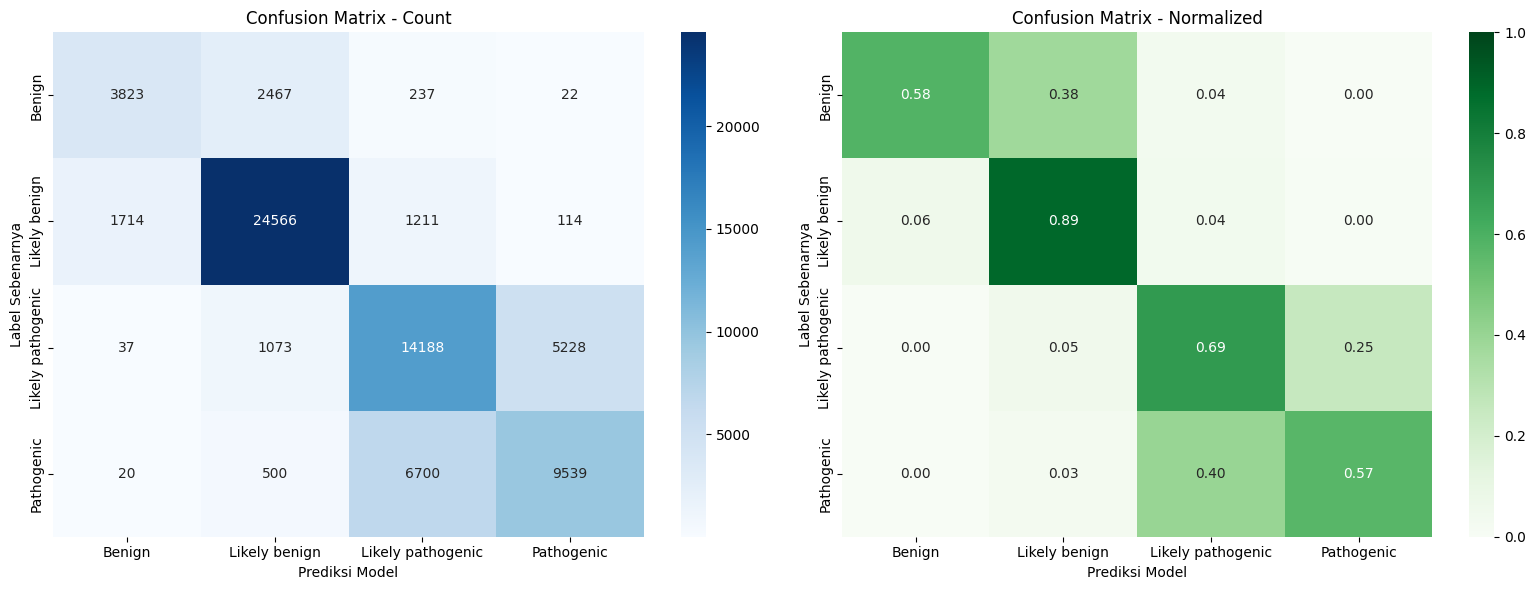


Laporan evaluasi per kelas disimpan di: /content/drive/MyDrive/skripsi/data/Lampiran_Skripsi/evaluation_report_multiclass_4class_NoSMOTE.csv

+-- LAPORAN PER KELAS --
┌───────────────────┬────────────────────┬────────────────────┬────────────────────┬────────────────────┐
│ Kelas             │ precision          │ recall             │ f1-score           │ support            │
├───────────────────┼────────────────────┼────────────────────┼────────────────────┼────────────────────┤
│ Benign            │ 0.683410797282803  │ 0.583753244770194  │ 0.6296631804331714 │ 6549.0             │
│ Likely benign     │ 0.858770887226456  │ 0.8899112479623257 │ 0.8740637953425486 │ 27605.0            │
│ Likely pathogenic │ 0.6352077363896849 │ 0.6912208905778038 │ 0.6620316364145397 │ 20526.0            │
│ Pathogenic        │ 0.6400724686304771 │ 0.5691867056506952 │ 0.6025519550249511 │ 16759.0            │
│ accuracy          │ 0.7295174904463948 │ 0.7295174904463948 │ 0.7295174904463948 │ 0.729

In [ ]:
y_pred = best_model.predict(X_test[selected_features])
y_prob = best_model.predict_proba(X_test[selected_features])

acc     = accuracy_score(y_test, y_pred)
bal_acc = balanced_accuracy_score(y_test, y_pred)
prec    = precision_score(y_test, y_pred, average='macro', zero_division=0)
rec     = recall_score(y_test, y_pred, average='macro', zero_division=0)
f1      = f1_score(y_test, y_pred, average='macro', zero_division=0)

print('\n+-- METRIK EVALUASI TEST SET --')
print_kv_table({
    'Accuracy'       : f'{acc:.4f}',
    'Balanced Acc'   : f'{bal_acc:.4f}',
    'Precision Macro': f'{prec:.4f}',
    'Recall Macro'   : f'{rec:.4f}',
    'F1 Macro'       : f'{f1:.4f}',
}, key_label='Metrik', val_label='Nilai')

try:
    y_test_bin = label_binarize(y_test, classes=classes)
    roc_auc    = roc_auc_score(y_test_bin, y_prob, average='macro', multi_class='ovr')
    print(f'\nROC-AUC macro: {roc_auc:.4f}')
except ValueError:
    roc_auc = None
    print('\nROC-AUC macro tidak dapat dihitung.')

print('\nClassification Report:')
print(classification_report(y_test, y_pred, target_names=label_encoder.classes_, zero_division=0))

cm            = confusion_matrix(y_test, y_pred, labels=classes)
cm_normalized = confusion_matrix(y_test, y_pred, labels=classes, normalize='true')
labels_ordered = label_encoder.classes_

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels_ordered, yticklabels=labels_ordered, ax=axes[0])
axes[0].set_title('Confusion Matrix - Count')
axes[0].set_ylabel('Label Sebenarnya')
axes[0].set_xlabel('Prediksi Model')

sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Greens',
            xticklabels=labels_ordered, yticklabels=labels_ordered,
            ax=axes[1], vmin=0, vmax=1)
axes[1].set_title('Confusion Matrix - Normalized')
axes[1].set_ylabel('Label Sebenarnya')
axes[1].set_xlabel('Prediksi Model')
plt.tight_layout()

cm_path = LAMPIRAN_DIR / f'confusion_matrix{suffix}.png'
plt.savefig(cm_path, dpi=300, bbox_inches='tight')
print(f'\nVisualisasi Confusion Matrix disimpan di: {cm_path}')

plt.show()

report_dict = classification_report(y_test, y_pred, target_names=label_encoder.classes_,
                                    output_dict=True, zero_division=0)
report_df = pd.DataFrame(report_dict).transpose()
report_df.to_csv(EVAL_REPORT_PATH)
print(f'\nLaporan evaluasi per kelas disimpan di: {EVAL_REPORT_PATH}')
print('\n+-- LAPORAN PER KELAS --')
print_box_table(
    report_df[['precision', 'recall', 'f1-score', 'support']].reset_index()
    .rename(columns={'index': 'Kelas'})
)

## KURVA ROC ONE-VS-REST (OvR) + AUC PER KELAS



[TAHAP 6b/7] Evaluasi ROC-AUC One-vs-Rest (OvR) per Kelas

Kurva ROC (OvR) disimpan di: /content/drive/MyDrive/skripsi/data/Lampiran_Skripsi/roc_curve_ovr_4class_NoSMOTE.png


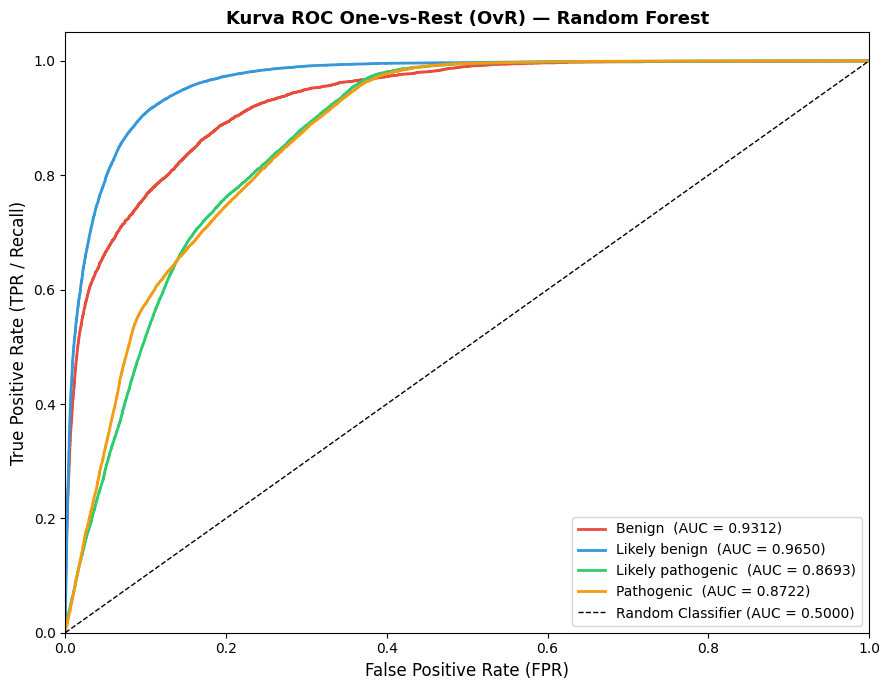


+-- AUC PER KELAS (One-vs-Rest) --
┌───────────────────┬────────┐
│ Kelas             │ AUC    │
├───────────────────┼────────┤
│ Benign            │ 0.9312 │
│ Likely benign     │ 0.9650 │
│ Likely pathogenic │ 0.8693 │
│ Pathogenic        │ 0.8722 │
└───────────────────┴────────┘

ROC-AUC Macro (OvR)  : 0.9094
ROC-AUC Macro (sklearn): 0.9094  [cross-check]
Tabel AUC per kelas disimpan di: /content/drive/MyDrive/skripsi/data/Lampiran_Skripsi/roc_auc_per_kelas_4class_NoSMOTE.csv


In [ ]:
print('\n' + '=' * 60)
print('[TAHAP 6b/7] Evaluasi ROC-AUC One-vs-Rest (OvR) per Kelas')
print('=' * 60)

y_test_bin   = label_binarize(y_test, classes=classes)
n_classes_   = len(classes)
PALETTE      = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12']

fig_roc, ax_roc = plt.subplots(figsize=(9, 7))
auc_per_class   = {}

for i in range(n_classes_):
    cls_name        = label_encoder.classes_[i]
    fpr, tpr, _     = roc_curve(y_test_bin[:, i], y_prob[:, i])
    auc_val         = sklearn_auc(fpr, tpr)
    auc_per_class[cls_name] = round(auc_val, 4)
    ax_roc.plot(
        fpr, tpr,
        color=PALETTE[i % len(PALETTE)],
        lw=2,
        label=f'{cls_name}  (AUC = {auc_val:.4f})',
    )

ax_roc.plot([0, 1], [0, 1], 'k--', lw=1, label='Random Classifier (AUC = 0.5000)')
ax_roc.set_xlabel('False Positive Rate (FPR)', fontsize=12)
ax_roc.set_ylabel('True Positive Rate (TPR / Recall)', fontsize=12)
ax_roc.set_title('Kurva ROC One-vs-Rest (OvR) — Random Forest', fontsize=13, fontweight='bold')
ax_roc.legend(loc='lower right', fontsize=10)
ax_roc.set_xlim([0.0, 1.0])
ax_roc.set_ylim([0.0, 1.05])
plt.tight_layout()

roc_path = LAMPIRAN_DIR / f'roc_curve_ovr{suffix}.png'
plt.savefig(roc_path, dpi=300, bbox_inches='tight')
print(f'\nKurva ROC (OvR) disimpan di: {roc_path}')
plt.show()

macro_roc_auc = sum(auc_per_class.values()) / len(auc_per_class)

print('\n+-- AUC PER KELAS (One-vs-Rest) --')
print_kv_table(
    {k: f'{v:.4f}' for k, v in auc_per_class.items()},
    key_label='Kelas', val_label='AUC'
)
print(f'\nROC-AUC Macro (OvR)  : {macro_roc_auc:.4f}')
if roc_auc is not None:
    print(f'ROC-AUC Macro (sklearn): {roc_auc:.4f}  [cross-check]')

auc_df = pd.DataFrame([
    {'Kelas': k, 'AUC': v} for k, v in auc_per_class.items()
] + [{'Kelas': 'Macro (rata-rata)', 'AUC': round(macro_roc_auc, 4)}])
auc_csv_path = LAMPIRAN_DIR / f'roc_auc_per_kelas{suffix}.csv'
auc_df.to_csv(auc_csv_path, index=False)
print(f'Tabel AUC per kelas disimpan di: {auc_csv_path}')

## 7. SIMPAN MODEL FINAL


In [ ]:
print('\n[TAHAP 7/7] Menyimpan model final dan semua artefak...')
results_df.to_csv(RESULTS_PATH, index=False)

joblib.dump({
    'model'                     : best_model,
    'available_features'        : available_features,
    'selected_features'         : selected_features,
    'feature_selection_spearman': spearman_corr.to_dict(),
    'feature_importance'        : feature_importance.to_dict(),
    'best_params'               : best_params,
    'label_encoder_classes'     : label_encoder.classes_.tolist(),
    'cv_results'                : results_df.to_dict(orient='records'),
    'roc_auc_macro'             : roc_auc,
    'roc_auc_per_kelas'         : auc_per_class,
    'roc_auc_macro_manual'      : macro_roc_auc,
}, MODEL_PATH)

print('\n+-- FILE YANG DISIMPAN --')
print_kv_table({
    'Model final'         : str(MODEL_PATH),
    'Hasil tuning CV'     : str(RESULTS_PATH),
    'Laporan evaluasi'    : str(EVAL_REPORT_PATH),
    'Lampiran 81 trials'  : str(LAMPIRAN_CV_TRIALS_PATH),
    'Ckpt feat. import.'  : str(CKPT_FEAT_IMP),
    'Ckpt trials'         : str(CKPT_TRIALS),
    'Ckpt best model'     : str(CKPT_BEST_MDL),
}, key_label='Artefak', val_label='Path')

print('\nTAHAP 4 SELESAI!')



[TAHAP 7/7] Menyimpan model final dan semua artefak...

+-- FILE YANG DISIMPAN --
┌────────────────────┬──────────────────────────────────────────────────────────────────────────────────────────────────────┐
│ Artefak            │ Path                                                                                                 │
├────────────────────┼──────────────────────────────────────────────────────────────────────────────────────────────────────┤
│ Model final        │ /content/drive/MyDrive/skripsi/data/random_forest_model_4class_NoSMOTE.pkl                           │
│ Hasil tuning CV    │ /content/drive/MyDrive/skripsi/data/training_results_4class_NoSMOTE.csv                              │
│ Laporan evaluasi   │ /content/drive/MyDrive/skripsi/data/Lampiran_Skripsi/evaluation_report_multiclass_4class_NoSMOTE.csv │
│ Lampiran 81 trials │ /content/drive/MyDrive/skripsi/data/Lampiran_Skripsi/cv_81_trials_4class_NoSMOTE.csv                 │
│ Ckpt feat. import. │ /content/dri